<img src="https://github.com/hernancontigiani/ceia_memorias_especializacion/raw/master/Figures/logoFIUBA.jpg" width="500" align="center">

# **Visión por Computadora 3D**
# **Tarea 2, Structure from Motion**

**Objetivo**

Reconstruir una escena en 3D a partir de un video común, implementando paso a paso el flujo de Structure from Motion, y analizar cómo influye cada parámetro en la calidad de la reconstrucción.

**Descripción**

En este notebook se parte de un video en el que la cámara se desplaza alrededor de una escena. Del video se extraen las fotografías más nítidas y en cada una se detectan puntos característicos con SIFT. Los puntos se emparejan entre fotografías mediante el test de Lowe y se verifican con RANSAC. Las correspondencias se encadenan en tracks, y con el par inicial se estiman la pose relativa y una primera nube de puntos. Luego se incorporan las demás fotografías una a una, estimando su pose con PnP y triangulando nuevos puntos. El bundle adjustment refina en conjunto las cámaras, los puntos y la distancia focal. Al final se modifican los parámetros principales del flujo y se reconstruye una escena propia.

---
#### **Instrucciones:**
Utilice este notebook como base para realizar el TP2. Ejecútelo primero sin cambios y registre los resultados como línea de base. En cada ejercicio modifique solo lo indicado. Restablezca el valor original antes del siguiente ejercicio.

1. **Otro video (punto adicional con video propio)** Reconstruya otra escena con un video del repositorio de VGGT (https://github.com/facebookresearch/vggt/tree/main/examples/videos) o con un video propio.
¿Qué zonas de la escena tienen menos puntos y por qué?

2. **Cinco vecinos** En bf.knnMatch, reemplace k=2 por k=5.
¿Cambian los resultados? Explique por qué.

3. **Test de Lowe**: Reemplace 0.8 por 0.6 y luego por 0.95.

¿Cómo varían las parejas y los puntos 3D?
¿Por qué aceptar más parejas no produce más puntos?

4. **Menos features:** reemplace cv2.SIFT_create(3000) por cv2.SIFT_create(1000).

¿Qué ocurre con los puntos 3D y el tiempo?

5. **Menos fotografías:** Reemplace N = 24 por N = 12.

¿Se registran todas las cámaras?


6. **Ángulo de triangulación:** En triangular_nuevos, reemplace > 1.5 por > 3.

¿Cuántos puntos se pierden?
¿Por qué un ángulo pequeño da una profundidad poco confiable?

Entregue el notebook descargado en este link https://forms.gle/t1jjETaro6mfrdCY9 con las celdas ejecutadas, de modo que se vean las salidas, los gráficos y sus respuestas

---

**Este notebook reproduce el flujo visto en clase, pero aplicado a un video propio. Si graba su propio video, desplácese alrededor de la escena con lentitud, mantenga el enfoque y evite el zoom. El video usado en este notebook está en https://drive.google.com/file/d/1BjvKU6H2i85Fe0rU3-XfSFuzxwiXl--y/view?usp=sharing**

**Preparación.** Se descarga el mismo `gato.mp4` de la consigna si todavía no está en la carpeta del notebook. Solo se adapta la ruta para poder correrlo en Colab o Jupyter. Se usa OpenCV 4.13 en las corridas de esta entrega.

In [1]:
from pathlib import Path

RUTA_VIDEO = Path("gato.mp4")
if not RUTA_VIDEO.is_file():
    import gdown
    gdown.download(id="1BjvKU6H2i85Fe0rU3-XfSFuzxwiXl--y", output=str(RUTA_VIDEO), quiet=False)
print("video:", RUTA_VIDEO)

video: gato.mp4


importamos lo necesario

In [2]:
import time
import numpy as np
import cv2
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from scipy.optimize import least_squares
from scipy.sparse import lil_matrix
from scipy.spatial.transform import Rotation

**0.- Las fotos**

* la cámara se mueve alrededor de la escena (tu video)
* cortamos el video en N tramos y en cada uno nos quedamos con el cuadro más nítido (varianza del Laplaciano)

**Cambio de organización.** Las etapas de cálculo se pueden llamar de nuevo desde los ejercicios. Así se reutilizan los mismos pasos de la base y se evita duplicar código. Cada etapa reemplaza el estado de la corrida anterior.

**Uso de memoria.** Se recorre el video dos veces. La primera pasada guarda solo los valores de nitidez y la segunda conserva los cuadros elegidos. Así mantenemos los mismos tramos, el mismo criterio de selección y la misma resolución con menos memoria.

In [3]:
def seleccionar_fotos(ruta, n_fotos, mostrar=True):
    global N, fotos, grises, H, W
    N = n_fotos
    ANCHO_MAX = 1280

    def reducir(fr):
        if fr.shape[1] > ANCHO_MAX:
            alto = round(fr.shape[0] * ANCHO_MAX / fr.shape[1])
            fr = cv2.resize(fr, (ANCHO_MAX, alto), interpolation=cv2.INTER_AREA)
        return fr

    # Primera pasada: calculamos qué tan nítido es cada cuadro y guardamos solo ese valor.
    cap = cv2.VideoCapture(str(ruta))
    nitidez = []
    try:
        while True:
            ok, fr = cap.read()
            if not ok:
                break
            gris = cv2.cvtColor(reducir(fr), cv2.COLOR_BGR2GRAY)
            nitidez.append(cv2.Laplacian(gris, cv2.CV_64F).var())
    finally:
        cap.release()

    if len(nitidez) < N:
        raise ValueError(f"{ruta}: se necesitan al menos {N} cuadros legibles.")

    # El mismo criterio de la base: el más nítido de cada tramo.
    elegidos = {t[np.argmax([nitidez[i] for i in t])] for t in np.array_split(np.arange(len(nitidez)), N)}

    # Segunda pasada: conservamos solo las fotos elegidas, en orden de aparición.
    cap = cv2.VideoCapture(str(ruta))
    fotos = []
    try:
        for i in range(max(elegidos) + 1):
            ok, fr = cap.read()
            if not ok:
                raise ValueError(f"{ruta}: no se pudo volver a leer el cuadro {i}.")
            if i in elegidos:
                fotos.append(cv2.cvtColor(reducir(fr), cv2.COLOR_BGR2RGB))
    finally:
        cap.release()

    grises = [cv2.cvtColor(f, cv2.COLOR_RGB2GRAY) for f in fotos]
    H, W = grises[0].shape
    if mostrar:
        print(f"{len(nitidez)} cuadros en el video -> {N} fotos de {W} × {H}")

In [4]:
# El temporizador suma solo las etapas de cálculo, sin incluir las visualizaciones.
tiempos = {}

def medir(etapa, funcion, *args, **kwargs):
    inicio = time.perf_counter()
    resultado = funcion(*args, **kwargs)
    tiempos[etapa] = tiempos.get(etapa, 0) + time.perf_counter() - inicio
    return resultado

medir("Fotos", seleccionar_fotos, RUTA_VIDEO, 24)

516 cuadros en el video -> 24 fotos de 576 × 1024


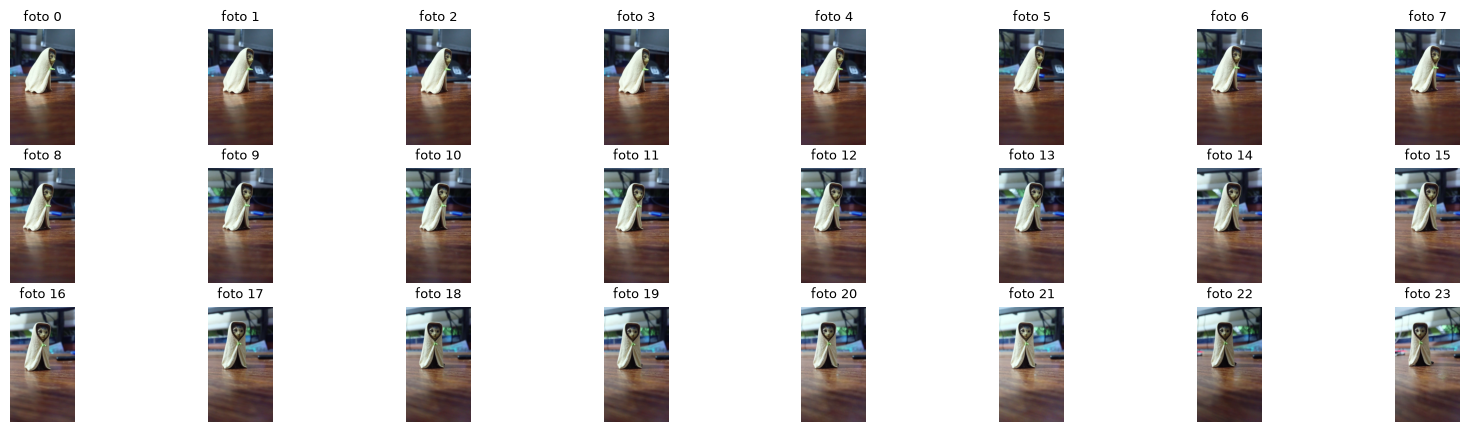

In [5]:
fig, ax = plt.subplots(int(np.ceil(N / 8)), 8, figsize=(20, 1.7 * np.ceil(N / 8)))
for k, a in enumerate(ax.ravel()):
    a.axis("off")
    if k < N: a.imshow(fotos[k]); a.set_title(f"foto {k}", fontsize=9)
plt.show()

**1.- Features**

puntos distintivos en cada foto

SIFT busca en cada foto puntos que se puedan volver a encontrar desde otro lugar: esquinas y manchas, a la escala en que aparecen.

Cada uno tiene una posición, una escala, una orientación y un descriptor de 128 números

In [6]:
def detectar_features(n_features=3000, mostrar=True):
    global kps, descs, xy
    # buscamos hasta n_features puntos característicos por foto: esquinas o manchas que se
    # pueden reconocer aunque la foto se haya tomado desde otro lugar
    sift = cv2.SIFT_create(n_features)

    # para cada foto devuelve:
    # kps (keypoints): posición, escala (tamaño) y orientación de cada punto
    # descs: un descriptor de 128 números por punto, funciona como una “huella digital” del punto
    kps, descs = zip(*[sift.detectAndCompute(g, None) for g in grises])

    # xy guarda solo las coordenadas (u, v) en píxeles
    xy = [np.float64([k.pt for k in ks]) for ks in kps]
    if mostrar:
        print(f"features por foto: entre {min(map(len, kps))} y {max(map(len, kps))}")

medir("SIFT", detectar_features)

features por foto: entre 343 y 503


los features de la primera foto: el círculo es la escala y la línea la orientación

se concentran donde hay textura, por ejemplo en los bordes y los detalles del pelaje

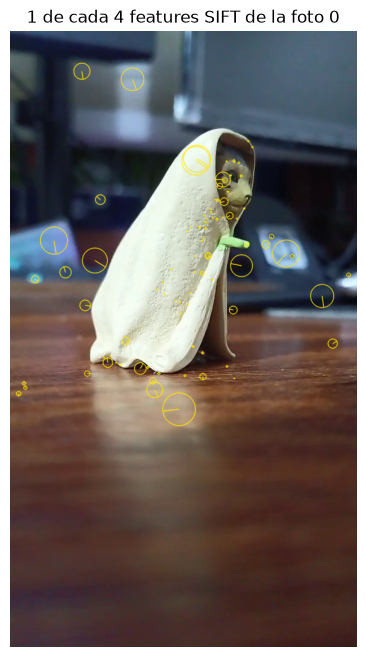

In [7]:
vis = cv2.drawKeypoints(fotos[0], kps[0][::4], None, color=(255, 230, 0), flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
plt.figure(figsize=(14, 8))
plt.imshow(vis)
plt.axis("off")
plt.title("1 de cada 4 features SIFT de la foto 0")
plt.show()

**2.- Matching**

el mismo punto en dos fotos

para cada par de fotos:
* para cada descriptor de una foto buscamos los 2 más parecidos en la otra
* **test de Lowe:** aceptamos si el mejor es claramente mejor que el segundo (distancia < 0.8 × la segunda)
* **RANSAC** sobre la matriz fundamental: descartamos las parejas que no cumplen x₂ᵀ F x₁ = 0

como es un video, comparamos cada foto con las 10 siguientes

**Cambios en matching.** Se exponen `k` y el umbral de Lowe para los ejercicios 2 y 3. Para `k=5`, se siguen comparando las distancias de los dos mejores vecinos. Se cuenta cuántas parejas pasan Lowe, incluso en pares de fotos que después se descartan. El mensaje de salida indica el umbral real de 10 inliers que ya usaba la base.

In [8]:
bf = cv2.BFMatcher()
def emparejar(i, j, k, lowe):
    # Lowe usa los dos mejores, aunque se pidan más vecinos.
    vecinos = bf.knnMatch(descs[i], descs[j], k=k)
    ms = [v[0] for v in vecinos if len(v) >= 2 and v[0].distance < lowe * v[1].distance]
    a = np.array([m.queryIdx for m in ms])
    b = np.array([m.trainIdx for m in ms])

    if len(ms) < 20:
      return len(ms), None

    # Estimamos la matriz fundamental F con RANSAC y descartamos las parejas que no cumplen la geometría
    F, ok = cv2.findFundamentalMat(xy[i][a], xy[j][b], cv2.FM_RANSAC, 1.0, 0.999)
    if F is None:
      return len(ms), None
    ok = ok.ravel() > 0
    return len(ms), {"a": a, "b": b, "ok": ok, "F": F}


def hacer_matching(k=2, lowe=0.8, mostrar=True):
    global pares, total_lowe
    VENTANA = 10  # con cuántas fotos siguientes comparamos cada una (subilo a N si tu video vuelve al punto de partida)
    total_lowe = 0
    pares = {}
    for i in range(N):
        # Comparamos cada foto con las VENTANA siguientes
        for j in range(i + 1, min(i + 1 + VENTANA, N)):
            n_lowe, r = emparejar(i, j, k, lowe)
            total_lowe += n_lowe
            # Guardamos el par solo si tiene al menos 10 parejas verificadas
            if r is not None and r["ok"].sum() >= 10:
              pares[(i, j)] = r
    if mostrar:
        print(f"{len(pares)} pares de fotos con al menos 10 parejas verificadas.")

medir("Matching", hacer_matching)

185 pares de fotos con al menos 10 parejas verificadas.


un par de fotos: en verde las parejas que pasaron RANSAC, en rojo las que pasaron Lowe pero no la geometría

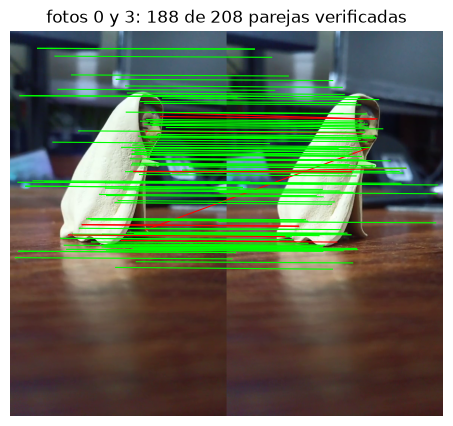

In [9]:
def dibujar_par(i, j, n=120):
    r = pares[(i, j)]
    # Elegimos al azar hasta 120 parejas para no saturar el dibujo
    sel = np.random.default_rng(0).choice(len(r["a"]), min(n, len(r["a"])), replace=False)
    # Ponemos las dos fotos lado a lado
    plt.figure(figsize=(18, 5)); plt.imshow(np.hstack([fotos[i], fotos[j]])); plt.axis("off")
    for k in sel:
        p, q = xy[i][r["a"][k]], xy[j][r["b"][k]]
        # Unimos cada pareja con una línea: verde si pasó RANSAC, roja si no (sumamos W porque la segunda foto está a la derecha)
        plt.plot([p[0], q[0] + W], [p[1], q[1]], color="lime" if r["ok"][k] else "red", lw=0.8)
    plt.title(f"fotos {i} y {j}: {r['ok'].sum()} de {len(r['a'])} parejas verificadas")
    plt.show()

# dibujamos el par con más parejas verificadas entre fotos separadas por al menos 2 cuadros
par_demo = max([k for k in pares if k[1] - k[0] >= 2] or list(pares), key=lambda k: pares[k]["ok"].sum())
dibujar_par(*par_demo)

cuántas parejas verificadas hay entre cada par de fotos. Las fotos cercanas en el video comparten mucho; a medida que se separan en el recorrido, cada vez menos

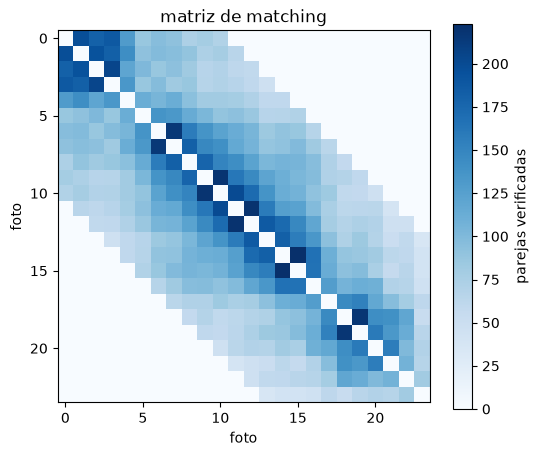

In [10]:
M = np.zeros((N, N))
# Llenamos la matriz con la cantidad de parejas verificadas de cada par (es simétrica)
for (i, j), r in pares.items(): M[i, j] = M[j, i] = r["ok"].sum()
# Mostramos la matriz como imagen: más oscuro = más parejas en común
plt.figure(figsize=(6, 5)); plt.imshow(M, cmap="Blues"); plt.colorbar(label="parejas verificadas")
plt.xlabel("foto")
plt.ylabel("foto")
plt.title("matriz de matching")
plt.show()

**tracks:** encadenamos las parejas. Si el feature 12 de la foto 0 es el 40 de la foto 1, y ese es el 7 de la foto 2, los tres son el **mismo punto 3D**. Lo hacemos con union-find: cada feature arranca en su propio grupo y cada pareja une dos grupos

In [11]:
def armar_tracks(mostrar=True):
    global padre, tracks, track_de, largos
    padre = {}
    # Buscamos la raíz del grupo de un nodo y acortamos el camino para que sea más rápido
    def raiz(n):
        while padre.setdefault(n, n) != n:
            padre[n] = padre[padre[n]]
            n = padre[n]
        return n

    # Unimos en un mismo grupo cada pareja verificada (un nodo es (foto, índice del feature))
    for (i, j), r in pares.items():
        for p, q in zip(r["a"][r["ok"]], r["b"][r["ok"]]):
            padre[raiz((i, p))] = raiz((j, q))

    grupos = {}
    for n in list(padre):
      grupos.setdefault(raiz(n), []).append(n)

    # Nos quedamos con los grupos que no tienen dos features de la misma foto: cada uno es un track
    tracks = [sorted(g) for g in grupos.values() if len(g) >= 2 and len({f for f, _ in g}) == len(g)]

    # Armamos el índice inverso: para cada foto, de feature a track
    track_de = [dict() for _ in range(N)]
    for t, g in enumerate(tracks):
        for f, k in g:
          track_de[f][k] = t

    largos = np.array([len(t) for t in tracks])

    if mostrar:
        print(f"{len(tracks)} tracks | largo medio {largos.mean():.1f} fotos | el más largo: {largos.max()} fotos")

medir("Tracks", armar_tracks)

1316 tracks | largo medio 5.0 fotos | el más largo: 23 fotos


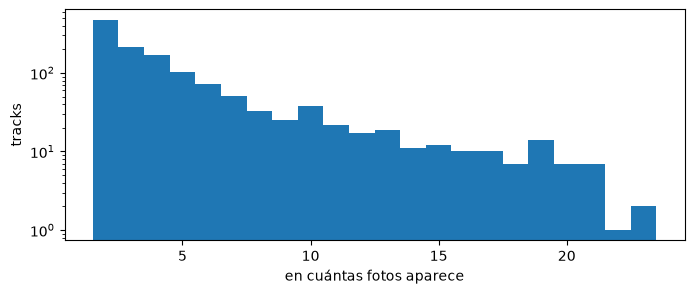

In [12]:
# Graficamos en cuántas fotos aparece cada track
plt.figure(figsize=(8, 3))
plt.hist(largos, bins=np.arange(2, largos.max() + 2) - 0.5)
plt.xlabel("en cuántas fotos aparece")
plt.ylabel("tracks")
plt.yscale("log")
plt.show()

**un punto, muchas fotos:** el track más largo. Es el mismo lugar del mundo visto desde todo el recorrido de la cámara

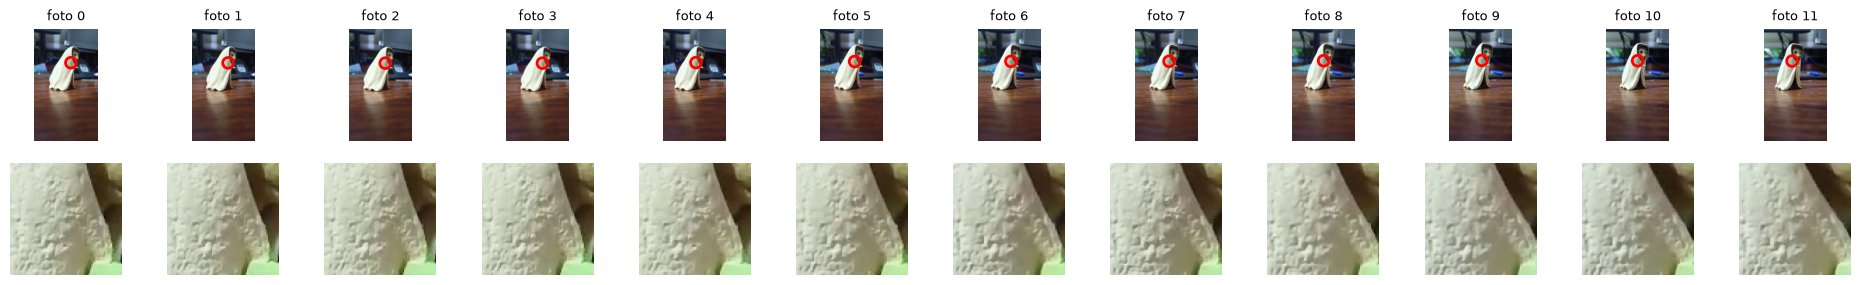

In [13]:
# Buscamos el track más largo
t = int(np.argmax(largos))
# Tomamos hasta 12 de sus observaciones, repartidas a lo largo del recorrido
obs = tracks[t][:: max(1, len(tracks[t]) // 12)][:12]
fig, ax = plt.subplots(2, len(obs), figsize=(2 * len(obs), 3.2))
for k, (f, i) in enumerate(obs):
    u, v = xy[f][i]
    # Arriba: marcamos el punto con un círculo rojo en la foto completa
    ax[0, k].imshow(fotos[f]); ax[0, k].scatter(u, v, s=60, facecolors="none", edgecolors="red", lw=2)
    # Abajo: hacemos zoom recortando 40 px alrededor del punto
    ax[1, k].imshow(fotos[f][max(0, int(v) - 40):int(v) + 40, max(0, int(u) - 40):int(u) + 40])
    ax[0, k].set_title(f"foto {f}", fontsize=9)
for a in ax.ravel(): a.axis("off")
plt.show()

## **3.- Geometría de dos vistas**

E, R y t entre cámaras

* arrancamos con un par de fotos

* tiene que tener muchas parejas, pero también buena separación: con fotos casi iguales los rayos son paralelos y la triangulación es mala

* no conocemos K

* suponemos el centro óptico en el medio de la imagen, la focal la vemos enseguida

In [14]:
# Armamos la matriz de calibración K con la focal f y el centro en el medio de la imagen
def K_de(f):
    return np.array([[f, 0, W / 2], [0, f, H / 2], [0, 0, 1]])

# Triangulamos con DLT: cada observación aporta 2 filas a A y el punto 3D es el último vector singular
def triangular(Ps, uvs):
    A = np.concatenate([np.stack([uv[:, :1] * P[2] - P[0], uv[:, 1:] * P[2] - P[1]], 1) for P, uv in zip(Ps, uvs)], 1)
    X = np.linalg.svd(A)[2][:, -1]
    return X[:, :3] / X[:, 3:]

# Proyectamos puntos 3D en la cámara P: devolvemos el píxel y la profundidad
def proyectar_P(P, X):
    h = np.c_[X, np.ones(len(X))] @ P.T
    return h[:, :2] / h[:, 2:], h[:, 2]

def dos_vistas(i, j, f):
    r = pares[(i, j)]
    p, q = xy[i][r["a"][r["ok"]]], xy[j][r["b"][r["ok"]]]
    K = K_de(f)
    # Calculamos E = Kᵀ F K y recuperamos la pose (R, t) que deja los puntos delante de las cámaras
    _, R, t, _ = cv2.recoverPose(K.T @ r["F"] @ K, p, q, K)
    # Ubicamos la primera cámara en el origen y la segunda con (R, t)
    P1, P2 = K @ np.c_[np.eye(3), np.zeros(3)], K @ np.c_[R, t]
    X = triangular([P1, P2], [p, q])
    # Medimos el error de reproyección promedio entre las dos fotos
    e = (np.linalg.norm(proyectar_P(P1, X)[0] - p, axis=1) + np.linalg.norm(proyectar_P(P2, X)[0] - q, axis=1)) / 2
    # Calculamos el ángulo entre los rayos de las dos cámaras hacia cada punto
    C2 = -R.T @ t.ravel()
    cos = (X * (X - C2)).sum(1) / np.linalg.norm(X, axis=1) / np.linalg.norm(X - C2, axis=1)
    return R, t.ravel(), np.median(e), np.degrees(np.median(np.arccos(np.clip(cos, -1, 1))))

las rectas epipolares de ese par: cada punto de la foto izquierda tiene que tener su pareja sobre la recta del mismo color

In [15]:
def elegir_par_inicial(mostrar=True):
    global f_ini, A0, B0, R_ini, t_ini
    f_ini = 1.2 * max(W, H)

    f0 = 1.2 * W
    candidatos = []
    for (i, j), r in pares.items():
        if 4 <= j - i <= 10:
            _, _, _, ang = dos_vistas(i, j, f0)
            candidatos.append((r["ok"].sum() if ang > 3 else 0, i, j, ang))
    # si tu video no tiene pares separados entre 4 y 10 fotos (pocas fotos, o mucho movimiento), probamos con todos
    if not candidatos:
        for (i, j), r in pares.items():
            _, _, _, ang = dos_vistas(i, j, f0)
            candidatos.append((r["ok"].sum() if ang > 3 else 0, i, j, ang))
    _, A0, B0, ang = max(candidatos)
    if mostrar:
        print(f"par inicial: fotos {A0} y {B0} | {pares[(A0, B0)]['ok'].sum()} parejas | ángulo mediano {ang:.1f}°")


    # Calculamos la pose inicial con la focal elegida y mostramos cuánto giró la segunda cámara
    R_ini, t_ini, e_ini, _ = dos_vistas(A0, B0, f_ini)
    if mostrar:
        print(f"la cámara {B0} giró {np.degrees(np.arccos((np.trace(R_ini) - 1) / 2)):.1f}° | t = {t_ini.round(3)} (norma 1: sin escala)")

medir("Par inicial", elegir_par_inicial)

par inicial: fotos 0 y 4 | 129 parejas | ángulo mediano 4.8°
la cámara 4 giró 3.1° | t = [-0.859 -0.088  0.504] (norma 1: sin escala)


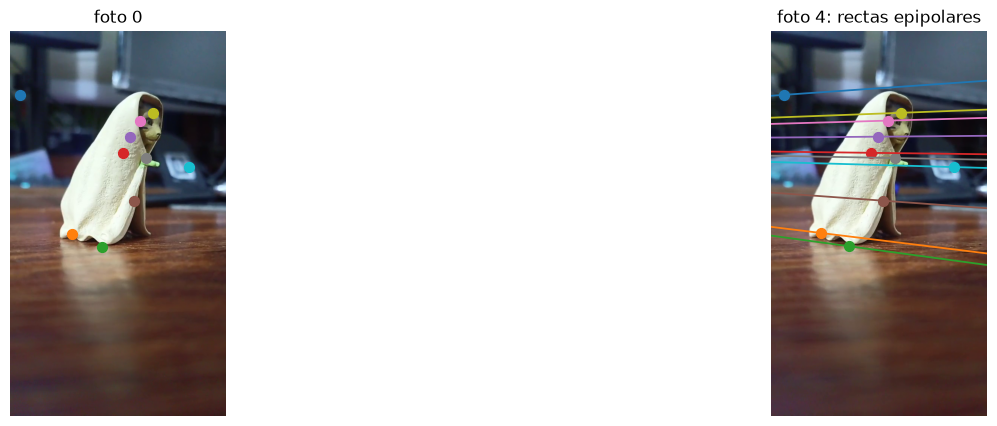

In [16]:
focales = np.arange(0.4, 2.01, 0.05) * W  # rango relativo al ancho, así sirve para cualquier resolución
errores = [dos_vistas(A0, B0, f)[2] for f in focales]

r = pares[(A0, B0)]
# Tomamos las parejas verificadas del par inicial
p, q = xy[A0][r["a"][r["ok"]]], xy[B0][r["b"][r["ok"]]]
# Elegimos 10 parejas repartidas para dibujar
sel = np.linspace(0, len(p) - 1, 10).astype(int)
fig, ax = plt.subplots(1, 2, figsize=(18, 5))
ax[0].imshow(fotos[A0]); ax[1].imshow(fotos[B0])
for c, k in zip(plt.cm.tab10(np.arange(10)), sel):
    # Calculamos la recta epipolar l = F·p del punto de la foto izquierda
    l = r["F"] @ [*p[k], 1]; u = np.array([0, W])
    # Dibujamos la recta en la foto derecha despejando v de la ecuación de la recta
    ax[1].plot(u, -(l[0] * u + l[2]) / l[1], color=c, lw=1.3)
    # Marcamos el punto y su pareja con el mismo color: la pareja debe caer sobre la recta
    ax[0].scatter(*p[k], color=c, s=50)
    ax[1].scatter(*q[k], color=c, s=50)
for a, tt in zip(ax, [f"foto {A0}", f"foto {B0}: rectas epipolares"]):
    a.set_xlim(0, W)
    a.set_ylim(H, 0)
    a.axis("off")
    a.set_title(tt)
plt.show()

E = Kᵀ F K tiene **4** descomposiciones posibles en (R, t). Solo una deja los puntos delante de las dos cámaras

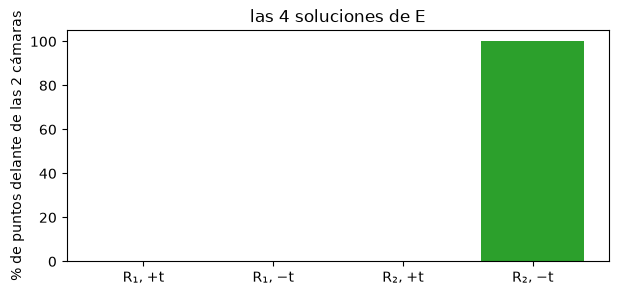

In [17]:
K = K_de(f_ini)

# Descomponemos E en sus 2 rotaciones posibles y la dirección de t
R1, R2, tt = cv2.decomposeEssentialMat(K.T @ r["F"] @ K)
P1 = K @ np.c_[np.eye(3), np.zeros(3)]
nombres, delante = [], []

# Probamos las 4 combinaciones de (R, t)
for nombre, R, t in [("R₁, +t", R1, tt), ("R₁, −t", R1, -tt), ("R₂, +t", R2, tt), ("R₂, −t", R2, -tt)]:
    X = triangular([P1, K @ np.c_[R, t]], [p, q])
    # Contamos qué porcentaje de puntos queda delante de las dos cámaras (z > 0 en ambas)
    nombres.append(nombre)
    delante.append(((X[:, 2] > 0) & ((X @ R.T + t.T)[:, 2] > 0)).mean() * 100)

# Graficamos y resaltamos en verde la única solución válida
plt.figure(figsize=(7, 3))
plt.bar(nombres, delante, color=["tab:green" if d == max(delante) else "tab:gray" for d in delante])
plt.ylabel("% de puntos delante de las 2 cámaras")
plt.title("las 4 soluciones de E"); plt.show()

**4.- Triangulación**


los puntos 3D

el estado de nuestra reconstrucción:
* **camaras:** para cada foto registrada, su pose como 6 números (rotación de Rodrigues + traslación)
* **puntos:** para cada track triangulado, su posición 3D
* **f:** la focal, compartida por todas las fotos

usamos la cámara de la primera foto (A0) como referencia para definir las coordenadas 3D

In [18]:
# Armamos la matriz de proyección P = K [R | t] a partir de los 6 números
def P_de(c, f):
    return K_de(f) @ np.c_[Rotation.from_rotvec(c[:3]).as_matrix(), c[3:]]

# Calculamos dónde está la cámara en el mundo: C = −Rᵀ t
def centro(c):
    return -Rotation.from_rotvec(c[:3]).as_matrix().T @ c[3:]

def iniciar_reconstruccion():
    global camaras, puntos, f
    # Guardamos cada cámara como 6 números (rotación + traslación): A0 queda en el origen
    camaras = {A0: np.zeros(6), B0: np.r_[Rotation.from_matrix(R_ini).as_rotvec(), t_ini]}
    puntos = {} # Guardamos aquí la posición 3D de cada track triangulado
    f = f_ini # Usamos una sola focal para todas las fotos

iniciar_reconstruccion()

Reconstruimos nuevos puntos 3D a partir de las correspondencias (tracks) observadas en al menos dos cámaras registradas:

1. Busca candidatos: identifica tracks que todavía no tienen coordenadas 3D y aparecen en al menos dos cámaras
2. Triangula: utiliza las matrices de proyección de las cámaras y DLT para calcular la posición 3D de cada punto
3. Valida los resultados: descarta puntos que estén detrás de alguna cámara o tengan un error de reproyección superior a 4 píxeles
4. Comprueba la geometría: exige un ángulo de triangulación superior a 1.5° para evitar reconstrucciones poco fiables
5. Guarda los puntos válidos: almacena sus coordenadas 3D en puntos

**Cambio en triangulación.** El ángulo mínimo queda como argumento con valor inicial de 1,5°. Se usa el mismo valor al triangular el primer par y al incorporar las demás cámaras.

In [19]:
def triangular_nuevos(angulo_min=1.5):
    # Buscamos los tracks sin punto 3D que aparecen en al menos 2 cámaras registradas
    cand = [t for t, g in enumerate(tracks) if t not in puntos and sum(fr in camaras for fr, _ in g) >= 2]
    nuevos = 0
    # Agrupamos por cantidad de observaciones para triangular muchos a la vez
    for n_obs in {sum(fr in camaras for fr, _ in tracks[t]) for t in cand}:
        ts = [t for t in cand if sum(fr in camaras for fr, _ in tracks[t]) == n_obs]
        obs = [[(fr, k) for fr, k in tracks[t] if fr in camaras] for t in ts]
        Ps = [[P_de(camaras[fr], f) for fr, _ in o] for o in obs]
        # Triangulamos con DLT: armamos A para cada track y resolvemos todo con una sola SVD
        A = np.array([np.concatenate([[x[0] * P[2] - P[0], x[1] * P[2] - P[1]] for P, (fr, k) in zip(Pl, o) for x in [xy[fr][k]]]) for Pl, o in zip(Ps, obs)])
        Xh = np.linalg.svd(A)[2][:, -1]; X = Xh[:, :3] / Xh[:, 3:]
        for t, o, x in zip(ts, obs, X):
            ok, rayos = True, []
            for fr, k in o:
                uv, z = proyectar_P(P_de(camaras[fr], f), x[None])
                # Descartamos el punto si queda detrás de una cámara o tiene más de 4 px de error
                if z[0] <= 0 or np.linalg.norm(uv[0] - xy[fr][k]) > 4: ok = False; break
                rayos.append((x - centro(camaras[fr])) / np.linalg.norm(x - centro(camaras[fr])))
            # Aceptamos el punto solo si el ángulo máximo entre rayos supera el umbral
            if ok and np.degrees(np.arccos(np.clip(min(a @ b for a in rayos for b in rayos), -1, 1))) > angulo_min:
                puntos[t] = x; nuevos += 1
    return nuevos


puntos_iniciales = medir("Reconstrucción", triangular_nuevos)
print(f"puntos triangulados con 2 fotos: {puntos_iniciales}")

puntos triangulados con 2 fotos: 83


vemos los puntos
* obtenemos los colores directamente de los píxeles de las fotografías originales

* para cada track toma el color del píxel correspondiente a su primera observación (g[0]) en la primera fotografía donde aparece

* cada punto 3D se visualiza con un color similar al que tenía en la imagen original
* las cámaras obtienen sus coordenadas a partir de sus parámetros de rotación y traslación, almacenados en el diccionario camaras

In [20]:
# Tomamos el color de cada track del píxel de la primera foto donde aparece
color_track = np.array([fotos[g[0][0]][int(xy[g[0][0]][g[0][1]][1]), int(xy[g[0][0]][g[0][1]][0])] for g in tracks]) / 255

# Dibujamos cada cámara como una pirámide: el vértice es el centro óptico y la base es la imagen
def piramide(c, f, tam):
    R = Rotation.from_rotvec(c[:3]).as_matrix(); C = centro(c)
    # Proyectamos las 4 esquinas de la imagen hacia adelante y las pasamos al sistema del mundo
    esquinas = np.array([[0, 0, 1], [W, 0, 1], [W, H, 1], [0, H, 1]]) @ np.linalg.inv(K_de(f)).T * tam
    E = esquinas @ R + C
    L = [C, E[0], None, C, E[1], None, C, E[2], None, C, E[3], None, E[0], E[1], E[2], E[3], E[0], None]
    return [(np.full(3, np.nan) if p is None else p) for p in L]

# Reordenamos los ejes a (X, Z, −Y) para que "arriba" quede hacia arriba en el gráfico
def a_vista(P):
    P = np.asarray(P); return P[:, 0], P[:, 2], -P[:, 1]

def figura(camaras, puntos, f, titulo, tam=None, max_puntos=6000):
    ts = np.array(sorted(puntos)); X = np.array([puntos[t] for t in ts])
    # Limitamos la cantidad de puntos para que el gráfico no se vuelva lento
    if len(ts) > max_puntos:
        k = np.random.default_rng(0).choice(len(ts), max_puntos, replace=False); ts, X = ts[k], X[k]
    tam = tam or 0.15 * np.median(np.linalg.norm(X - centro(camaras[A0]), axis=1))
    lineas = [p for c in camaras.values() for p in piramide(c, f, tam)]
    col = [f"rgb({r * 255:.0f},{g * 255:.0f},{b * 255:.0f})" for r, g, b in color_track[ts]]
    # Devolvemos los puntos con su color y las cámaras en rojo
    return [go.Scatter3d(x=a_vista(X)[0], y=a_vista(X)[1], z=a_vista(X)[2], mode="markers", marker=dict(size=1.5, color=col), name="puntos"),
            go.Scatter3d(x=a_vista(lineas)[0], y=a_vista(lineas)[1], z=a_vista(lineas)[2], mode="lines", line=dict(color="crimson", width=3), name="cámaras")]

fig = go.Figure(figura(camaras, puntos, f, ""))
fig.update_layout(height=550, title=f"2 cámaras y {len(puntos)} puntos", scene=dict(aspectmode="data", xaxis_visible=False, yaxis_visible=False, zaxis_visible=False), margin=dict(l=0, r=0, t=40, b=0))
fig.show()

**5.- Bundle Adjustment**


refinar todo junto

ajustamos **todo junto**: las poses de las cámaras registradas, los puntos y la focal, para minimizar el error de reproyección

Σ ‖ xᵢⱼ − π(f, Rᵢ, tᵢ, Xⱼ) ‖²

* la cámara A0 queda fija: es el origen del mundo
* el jacobiano es disperso: cada residuo depende de su cámara, su punto y la focal (notebook 2)
* las parejas malas que se colaron no las ablandamos con una pérdida robusta: después de cada ajuste borramos los puntos con alguna observación de más de 4 px

In [21]:
# Listamos todas las observaciones: qué cámara (ic), qué punto (ip) y dónde se midió (uv)
def observaciones():
    libres = [fr for fr in sorted(camaras) if fr != A0] # Ajustamos todas las cámaras menos A0
    ts = sorted(puntos)
    ic, ip, uv = [], [], []
    for n, t in enumerate(ts):
        for fr, k in tracks[t]:
            if fr in camaras:
                ic.append(-1 if fr == A0 else libres.index(fr)); ip.append(n); uv.append(xy[fr][k])
    return libres, ts, np.array(ic), np.array(ip), np.array(uv)

# Proyectamos todos los puntos en sus cámaras de una sola vez
def proyectar(cam, f, X, ic, ip):
    cam = np.r_[cam, np.zeros((1, 6))] # Usamos el índice −1 para la cámara fija A0
    Xc = Rotation.from_rotvec(cam[ic, :3]).apply(X[ip]) + cam[ic, 3:]
    return f * Xc[:, :2] / Xc[:, 2:] + [W / 2, H / 2]

# Medimos la distancia en píxeles entre lo proyectado y lo medido
def error_reproyeccion():
    libres, ts, ic, ip, uv = observaciones()
    cam = np.array([camaras[fr] for fr in libres]).reshape(-1, 6); X = np.array([puntos[t] for t in ts])
    return np.linalg.norm(proyectar(cam, f, X, ic, ip) - uv, axis=1)

def bundle_adjustment(max_iter=20, fijar_f=False):
    global f
    libres, ts, ic, ip, uv = observaciones()
    nc, npt, nf = len(libres), len(ts), 0 if fijar_f else 1
    # Definimos los residuos: la diferencia entre la proyección y la medición
    def residuos(v):
        ff = f if fijar_f else v[6 * nc]
        return (proyectar(v[:6 * nc].reshape(nc, 6), ff, v[6 * nc + nf:].reshape(npt, 3), ic, ip) - uv).ravel()
    # Armamos la matriz dispersa: cada residuo depende solo de su cámara, su punto y la focal
    A = lil_matrix((2 * len(uv), 6 * nc + nf + 3 * npt), dtype=int)
    filas = np.arange(len(uv)); libre = ic >= 0
    for s in range(6):
        A[2 * filas[libre], 6 * ic[libre] + s] = 1; A[2 * filas[libre] + 1, 6 * ic[libre] + s] = 1
    if nf: A[:, 6 * nc] = 1
    for s in range(3):
        A[2 * filas, 6 * nc + nf + 3 * ip + s] = 1; A[2 * filas + 1, 6 * nc + nf + 3 * ip + s] = 1
    # Juntamos todas las variables en un vector: cámaras, focal y puntos
    v0 = np.r_[np.array([camaras[fr] for fr in libres]).ravel(), [f] * nf, np.array([puntos[t] for t in ts]).ravel()]
    # Optimizamos todo junto por mínimos cuadrados
    sol = least_squares(residuos, v0, jac_sparsity=A, method="trf", x_scale="jac", max_nfev=max_iter)
    # Guardamos los valores ajustados
    for k, fr in enumerate(libres): camaras[fr] = sol.x[6 * k:6 * k + 6]
    if nf: f = sol.x[6 * nc]
    for k, t in enumerate(ts): puntos[t] = sol.x[6 * nc + nf + 3 * k:6 * nc + nf + 3 * k + 3]

# Borramos los puntos con alguna observación de más de `umbral` px
def limpiar(umbral=4):
    libres, ts, ic, ip, uv = observaciones()
    e = error_reproyeccion()
    malos = np.unique(ip[e > umbral])
    for n in malos: del puntos[ts[n]]
    return len(malos)

con solo 2 fotos ya hay algo para ajustar

In [22]:
def ajustar_inicio(mostrar=True):
    e0 = error_reproyeccion().mean() # Medimos el error antes de ajustar
    bundle_adjustment() # Ajustamos cámaras, puntos y focal con solo 2 fotos
    # Comparamos el error y la focal antes y después del ajuste
    if mostrar:
        print(f"error de reproyección: {e0:.2f} px -> {error_reproyeccion().mean():.2f} px | focal {f_ini:.0f} -> {f:.0f} px")

medir("Reconstrucción", ajustar_inicio)

error de reproyección: 2.31 px -> 0.17 px | focal 1229 -> 1383 px


**SfM incremental**

ahora repetimos foto por foto:
1. elegimos la foto no registrada que ve más puntos 3D ya triangulados
2. estimamos la pose de la nueva cámara utilizando puntos 3D conocidos y sus correspondencias 2D en la nueva fotografía
3. triangulamos los tracks nuevos que ahora ven 2 fotos registradas
4. bundle adjustment de todo, y limpiamos puntos malos

guardamos una foto del estado en cada paso para animarlo

In [23]:
def registrar_siguiente():
    K = K_de(f)
    mejor = None
    # Buscamos la foto no registrada que ve más puntos 3D ya triangulados
    for fr in range(N):
        if fr in camaras:
          continue
        pares2d3d = [(k, t) for k, t in track_de[fr].items() if t in puntos]
        if mejor is None or len(pares2d3d) > len(mejor[1]):
          mejor = (fr, pares2d3d)
    fr, p2d3d = mejor
    if len(p2d3d) < 30:
      return None
    obj = np.array([puntos[t] for _, t in p2d3d]); img = np.array([xy[fr][k] for k, _ in p2d3d])
    # Estimamos la pose de la foto nueva con PnP + RANSAC a partir de las parejas 2D–3D
    ok, rvec, tvec, inl = cv2.solvePnPRansac(obj, img, K, None, iterationsCount=500, reprojectionError=4.0)
    if not ok or inl is None or len(inl) < 30:
      return None
    camaras[fr] = np.r_[rvec.ravel(), tvec.ravel()] # Registramos la cámara nueva
    return fr, len(p2d3d), len(inl)

def reconstruir_incremental(angulo_min=1.5, mostrar=True):
    global historia
    historia = [(dict(camaras), dict(puntos), f, "inicio")] # Guardamos cada estado para la animación
    filas = []
    t0 = time.time()
    # Repetimos foto por foto hasta registrar todas
    while len(camaras) < N:
        r = registrar_siguiente()
        if r is None:
          if mostrar:
              print("ninguna foto más se puede registrar")
          break
        fr, n2d3d, n_inl = r
        nuevos = triangular_nuevos(angulo_min) # Triangulamos los puntos que ahora ven 2 cámaras
        antes = error_reproyeccion().mean()
        bundle_adjustment(max_iter=10) # Ajustamos todo junto
        borrados = limpiar() # Borramos los puntos malos
        despues = error_reproyeccion().mean()
        filas.append((len(camaras), fr, n2d3d, n_inl, nuevos, len(puntos), antes, despues, f))
        historia.append((dict(camaras), dict(puntos), f, f"+ foto {fr}"))
        if mostrar:
            print(f"{len(camaras):2d} cámaras | + foto {fr:2d} | PnP: {n_inl:4d}/{n2d3d:4d} inliers | +{nuevos:4d} puntos | total {len(puntos):5d} | error {antes:.2f} -> {despues:.2f} px | f {f:.0f} px")
    if mostrar:
        print(f"listo en {time.time() - t0:.0f} s")

medir("Reconstrucción", reconstruir_incremental)

 3 cámaras | + foto  1 | PnP:   68/  69 inliers | +  82 puntos | total   165 | error 0.26 -> 0.24 px | f 1421 px
 4 cámaras | + foto  2 | PnP:  113/ 113 inliers | +  12 puntos | total   177 | error 0.28 -> 0.27 px | f 1394 px
 5 cámaras | + foto  3 | PnP:  120/ 121 inliers | +   9 puntos | total   186 | error 0.29 -> 0.28 px | f 1377 px
 6 cámaras | + foto  5 | PnP:   85/  87 inliers | +  74 puntos | total   260 | error 0.35 -> 0.32 px | f 1256 px
 7 cámaras | + foto  6 | PnP:  121/ 125 inliers | +  60 puntos | total   312 | error 0.50 -> 0.47 px | f 1205 px
 8 cámaras | + foto  7 | PnP:  150/ 155 inliers | +  28 puntos | total   340 | error 0.54 -> 0.33 px | f 1077 px
 9 cámaras | + foto  8 | PnP:  136/ 138 inliers | +  92 puntos | total   431 | error 0.37 -> 0.34 px | f 1029 px
10 cámaras | + foto  9 | PnP:  172/ 174 inliers | +  78 puntos | total   508 | error 0.37 -> 0.34 px | f 962 px
11 cámaras | + foto 10 | PnP:  188/ 189 inliers | +  61 puntos | total   569 | error 0.35 -> 0.34

**la animación:** cada cuadro es el estado después de agregar una foto

In [24]:
# Calculamos límites fijos para los ejes, así la vista no salta entre cuadros
def ejes_de(camaras, puntos):
    X = np.array(list(puntos.values()) + [centro(c) for c in camaras.values()])
    # Usamos los percentiles 1 y 99 para ignorar puntos sueltos y agregamos un margen del 10 %
    lo, hi = np.percentile(X, 1, axis=0), np.percentile(X, 99, axis=0)
    pad = 0.1 * (hi - lo)
    lo, hi = lo - pad, hi + pad
    return dict(xaxis=dict(range=[lo[0], hi[0]], visible=False), yaxis=dict(range=[lo[2], hi[2]], visible=False),
                zaxis=dict(range=[-hi[1], -lo[1]], visible=False), aspectmode="manual",
                aspectratio=dict(x=1, y=(hi[2] - lo[2]) / (hi[0] - lo[0]), z=(hi[1] - lo[1]) / (hi[0] - lo[0])))

final_cam, final_pts = historia[-1][0], historia[-1][1]
# Fijamos el tamaño de las pirámides según el modelo final
tam = 0.12 * np.median(np.linalg.norm(np.array(list(final_pts.values())) - centro(final_cam[A0]), axis=1))
# Creamos un cuadro de animación por cada estado guardado en la historia
cuadros_anim = [go.Frame(data=figura(c, p, ff, "", tam, 4000), name=str(k), layout=go.Layout(title=f"{len(c)} cámaras, {len(p)} puntos ({nombre})"))
                for k, (c, p, ff, nombre) in enumerate(historia)]
fig = go.Figure(data=cuadros_anim[0].data, frames=cuadros_anim)
# Agregamos el botón de play y el slider para recorrer los pasos
fig.update_layout(height=650, scene=ejes_de(final_cam, final_pts), margin=dict(l=0, r=0, t=40, b=0), title=cuadros_anim[0].layout.title.text,
    updatemenus=[dict(type="buttons", x=0.05, y=0.05, buttons=[dict(label="▶ play", method="animate", args=[None, dict(frame=dict(duration=600, redraw=True), fromcurrent=True)])])],
    sliders=[dict(x=0.15, y=0.02, len=0.8, currentvalue=dict(prefix="paso "), steps=[dict(label=str(k), method="animate", args=[[str(k)], dict(mode="immediate", frame=dict(duration=0, redraw=True))]) for k in range(len(historia))])])
fig.show()


**7.- El resultado**

un último bundle adjustment largo (hasta 150 iteraciones), limpiando con un umbral más estricto (2 px)

In [25]:
def ajustar_final(mostrar=True):
    f_antes = f
    t0 = time.time()
    # Hacemos un ajuste largo, limpiamos con un umbral más estricto (2 px) y volvemos a ajustar
    bundle_adjustment(max_iter=150); limpiar(2); bundle_adjustment(max_iter=30)
    e = error_reproyeccion()
    if mostrar:
        print(f"{time.time() - t0:.0f} s | {len(camaras)} cámaras | {len(puntos)} puntos | error medio {e.mean():.2f} px | focal {f_antes:.0f} -> {f:.0f} px")
    return e.mean()

error_final = medir("Reconstrucción", ajustar_final)

18 s | 24 cámaras | 954 puntos | error medio 0.34 px | focal 873 -> 835 px


In [26]:
fig = go.Figure(figura(camaras, puntos, f, "", tam, 20000))
fig.update_layout(height=700, title="tu escena con nuestro SfM", scene=ejes_de(camaras, puntos), margin=dict(l=0, r=0, t=40, b=0))
fig.show()

cada punto del modelo, proyectado de vuelta sobre una foto: si la reconstrucción es buena, los puntos caen justo sobre los features que lo generaron

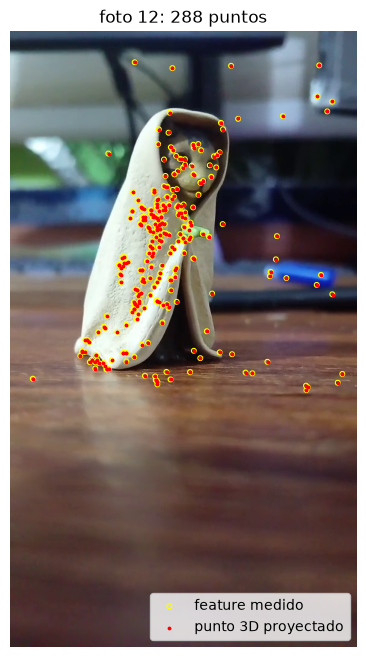

In [27]:
fr = sorted(camaras)[len(camaras) // 2] # Elegimos una foto del medio del recorrido
ts = [t for t in puntos if fr in {g for g, _ in tracks[t]}] # Buscamos los puntos 3D que se ven en esa foto
# Proyectamos los puntos 3D sobre la foto
uv_proy, _ = proyectar_P(P_de(camaras[fr], f), np.array([puntos[t] for t in ts]))
# Tomamos dónde se midió cada feature originalmente
uv_med = np.array([xy[fr][dict(tracks[t])[fr]] for t in ts])
plt.figure(figsize=(14, 8)); plt.imshow(fotos[fr])
# Comparamos: si la reconstrucción es buena, los puntos rojos caen dentro de los círculos amarillos
plt.scatter(*uv_med.T, s=12, facecolors="none", edgecolors="yellow", lw=0.8, label="feature medido")
plt.scatter(*uv_proy.T, s=3, c="red", label="punto 3D proyectado")
plt.legend(loc="lower right"); plt.axis("off"); plt.title(f"foto {fr}: {len(ts)} puntos"); plt.show()

Se agregaron métricas y gráficos para comparar las corridas. **Lowe** cuenta correspondencias 2D aceptadas antes de RANSAC en todos los pares evaluados. **RANSAC** suma las correspondencias verificadas de los pares que se conservaron. Un punto 3D puede reunir correspondencias de varios pares de fotos.

Los tiempos de la tabla corresponden a la corrida local en Windows.

In [28]:
def resumen():
    return {
        "Lowe": total_lowe,
        "RANSAC": sum(r["ok"].sum() for r in pares.values()),
        "Pares de fotos": len(pares),
        "Tracks": len(tracks),
        "Puntos iniciales": puntos_iniciales,
        "Puntos 3D": len(puntos),
        "Cámaras": f"{len(camaras)}/{N}",
        "Error medio (px)": round(error_final, 3),
        "SIFT (s)": round(tiempos["SIFT"], 2),
        "Matching (s)": round(tiempos["Matching"], 2),
        "Total (s)": round(sum(tiempos.values()), 2),
    }

resultados = {"Base": resumen()}
print(resultados["Base"])

{'Lowe': 26970, 'RANSAC': np.int64(19100), 'Pares de fotos': 185, 'Tracks': 1316, 'Puntos iniciales': 83, 'Puntos 3D': 954, 'Cámaras': '24/24', 'Error medio (px)': np.float64(0.34), 'SIFT (s)': 1.89, 'Matching (s)': 0.7, 'Total (s)': 44.42}


La función siguiente repite las etapas de la línea de base. Los valores por defecto son los originales, por eso en cada llamada solo hace falta indicar qué se quiere cambiar.

In [29]:
def iniciar_con_otro_par(angulo_min):
    global A0, B0, R_ini, t_ini, camaras, puntos
    par_original = (A0, B0, R_ini, t_ini, camaras, puntos)

    # Primero se prueban los pares con más coincidencias verificadas.
    candidatos = sorted(pares, key=lambda par: pares[par]["ok"].sum(), reverse=True)
    for i, j in candidatos:
        if (i, j) == par_original[:2]:
            continue
        R, t, error, angulo = dos_vistas(i, j, f_ini)
        if not (error < 6 and angulo > 2):
            continue
        A0, B0, R_ini, t_ini = i, j, R, t
        iniciar_reconstruccion()
        cantidad = triangular_nuevos(angulo_min)
        if cantidad < 30:
            continue
        registro = registrar_siguiente()
        if registro is not None:
            # PnP se usa para validar el par. La tercera cámara se agrega en el flujo normal.
            del camaras[registro[0]]
            print(f"Par alternativo: fotos {i} y {j}, {cantidad} puntos iniciales.")
            return cantidad

    A0, B0, R_ini, t_ini, camaras, puntos = par_original
    return len(puntos)


def hacer_prueba(nombre, ruta=RUTA_VIDEO, *, n_fotos=24, n_features=3000,
                 k=2, lowe=0.8, angulo_min=1.5, reintentar_par=False):
    global puntos_iniciales, error_final
    tiempos.clear()
    medir("Fotos", seleccionar_fotos, ruta, n_fotos, mostrar=False)
    medir("SIFT", detectar_features, n_features, mostrar=False)
    medir("Matching", hacer_matching, k, lowe, mostrar=False)
    medir("Tracks", armar_tracks, mostrar=False)
    medir("Par inicial", elegir_par_inicial, mostrar=False)
    iniciar_reconstruccion()
    puntos_iniciales = medir("Reconstrucción", triangular_nuevos, angulo_min)
    if reintentar_par and puntos_iniciales < 30:
        print(f"El primer par produjo {puntos_iniciales} puntos. Se prueban otros pares.")
        puntos_iniciales = medir("Reconstrucción", iniciar_con_otro_par, angulo_min)
    if puntos_iniciales:
        medir("Reconstrucción", ajustar_inicio, mostrar=False)
        medir("Reconstrucción", reconstruir_incremental, angulo_min, mostrar=False)
        error_final = medir("Reconstrucción", ajustar_final, mostrar=False)
    else:
        # Si el par inicial no produce puntos, no se puede estimar la pose siguiente con PnP.
        error_final = float("nan")
    resultados[nombre] = resumen()
    print(nombre, resultados[nombre])

# **Respuestas**

#### **1.- Otro video (punto adicional con video propio) Reconstruya otra escena con un video del repositorio de VGGT o con un video propio. ¿Qué zonas de la escena tienen menos puntos y por qué?**

#### 1a. Coliseo (VGGT)

**Agregado.** Se usa `Colosseum.mp4` de VGGT para reconstruir otra escena con los mismos parámetros de la base. El gráfico muestra la nube junto con las detecciones y los puntos reconstruidos que se ven en una foto. La descarga se guarda en una carpeta temporal para que funcione desde cualquier carpeta de trabajo.

In [32]:
from pathlib import Path
from tempfile import mkdtemp
from urllib.request import urlretrieve

ruta_coliseo = Path(mkdtemp(prefix="vpc3d_tp2_")) / "Colosseum.mp4"
urlretrieve(
    "https://raw.githubusercontent.com/facebookresearch/vggt/main/examples/videos/Colosseum.mp4",
    ruta_coliseo,
)
hacer_prueba("VGGT · Colosseum", ruta_coliseo)

VGGT · Colosseum {'Lowe': 264463, 'RANSAC': np.int64(244693), 'Pares de fotos': 185, 'Tracks': 7284, 'Puntos iniciales': 613, 'Puntos 3D': 5170, 'Cámaras': '24/24', 'Error medio (px)': np.float64(0.224), 'SIFT (s)': 1.02, 'Matching (s)': 5.57, 'Total (s)': 262.38}


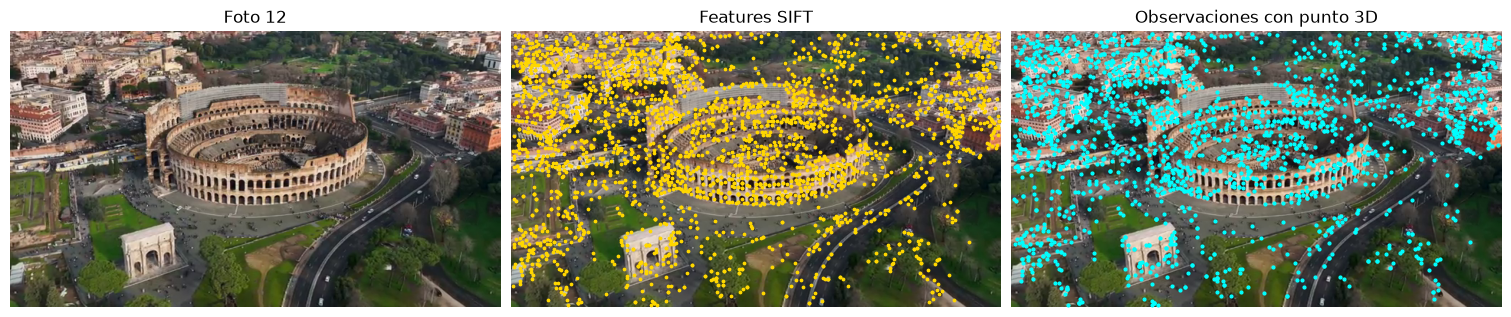

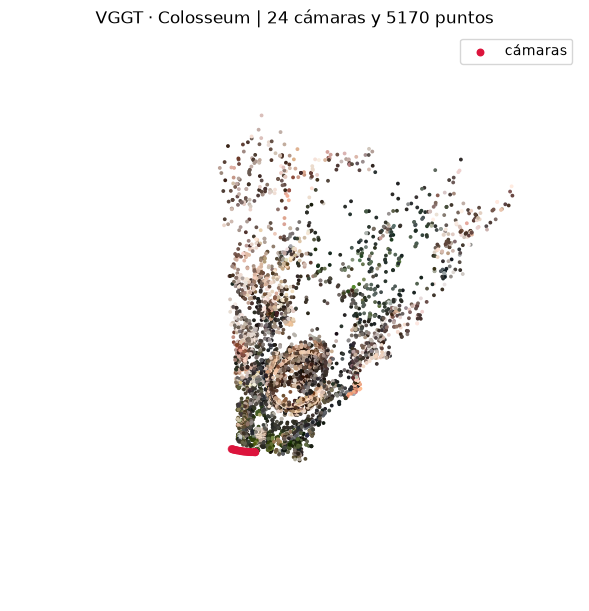

In [33]:
# Se elige la cámara registrada más cercana al centro del recorrido.
fr = min(camaras, key=lambda foto: abs(foto - N // 2))
visibles = [
    xy[foto][indice] for t in puntos for foto, indice in tracks[t] if foto == fr
]
fig, ax = plt.subplots(1, 3, figsize=(15, 5), layout="constrained")
for a in ax:
    a.imshow(fotos[fr])
    a.axis("off")
ax[0].set_title(f"Foto {fr}")
ax[1].scatter(*xy[fr].T, s=3, color="gold")
ax[1].set_title("Features SIFT")
ax[2].scatter(*np.array(visibles).T, s=4, color="cyan")
ax[2].set_title("Observaciones con punto 3D")
plt.show()

# Misma convención de ejes y colores que usa la nube del notebook base.
xyz = np.array(list(puntos.values()))
fig = plt.figure(figsize=(8, 6), layout="constrained")
ax = fig.add_subplot(projection="3d")
ax.scatter(*a_vista(xyz), c=[
    fotos[foto][int(xy[foto][indice, 1]), int(xy[foto][indice, 0])] / 255
    for foto, indice in (tracks[t][0] for t in puntos)
], s=3, depthshade=False)
ax.scatter(*a_vista([centro(c) for c in camaras.values()]), c="crimson", s=22, label="cámaras")
ax.set_title(f"VGGT · Colosseum | {len(camaras)} cámaras y {len(puntos)} puntos")
ax.set_axis_off()
ax.legend()
plt.show()

**Respuesta.** Se registraron 24/24 cámaras y quedaron 5.170 puntos 3D. En la foto 12 hay menos puntos reconstruidos en el centro de la calzada a la derecha, en el césped de la parte inferior y en algunos sectores en sombra. En el asfalto y el césped uniforme, SIFT encuentra pocos rasgos distintivos. En las sombras hay menos contraste y cuesta seguir los mismos detalles entre vistas. Los puntos se concentran en los arcos, las fachadas y los bordes de las veredas, donde hay más detalles que se pueden volver a identificar.

#### 1b. Video propio (zapatilla)

**Agregado.** Se seleccionan 16 fotogramas del video propio `20261128_143002.mp4`. Si el primer par produce menos de 30 puntos, se prueban otros pares y se verifica que al menos una tercera cámara se pueda registrar con PnP. El video debe estar en la carpeta de trabajo del notebook.


In [30]:
from pathlib import Path

ruta_video_propio = Path("20261128_143002.mp4")
if not ruta_video_propio.is_file():
    raise FileNotFoundError("Colocá 20261128_143002.mp4 en la carpeta de trabajo del notebook.")

hacer_prueba("Video propio", ruta_video_propio, n_fotos=16, reintentar_par=True)
if len(camaras) < 3 or not puntos:
    raise ValueError("La reconstrucción no pudo avanzar más allá de las dos primeras cámaras. Revisá las métricas anteriores.")


El primer par produjo 23 puntos. Se prueban otros pares.
Par alternativo: fotos 6 y 7, 1347 puntos iniciales.
Video propio {'Lowe': 49598, 'RANSAC': np.int64(30865), 'Pares de fotos': 105, 'Tracks': 9187, 'Puntos iniciales': 1347, 'Puntos 3D': 8028, 'Cámaras': '16/16', 'Error medio (px)': np.float64(0.189), 'SIFT (s)': 2.67, 'Matching (s)': 5.72, 'Total (s)': 175.02}


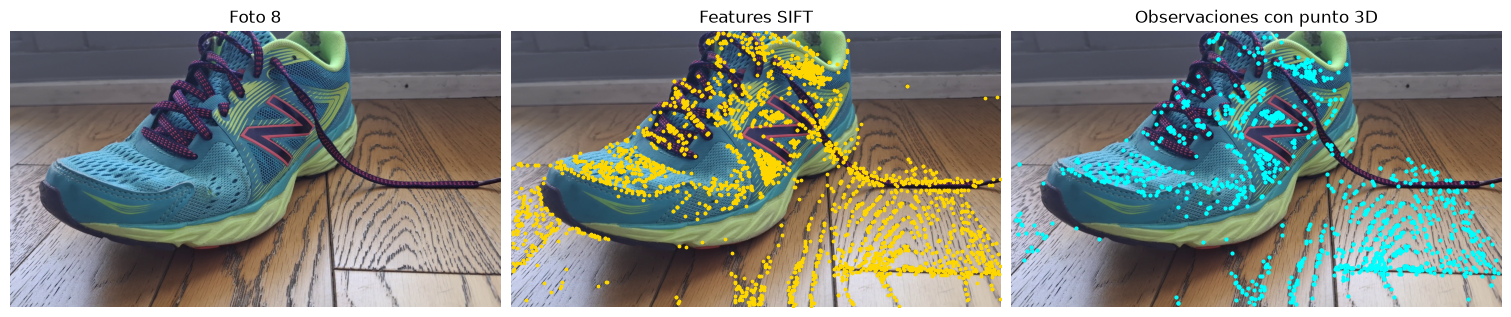

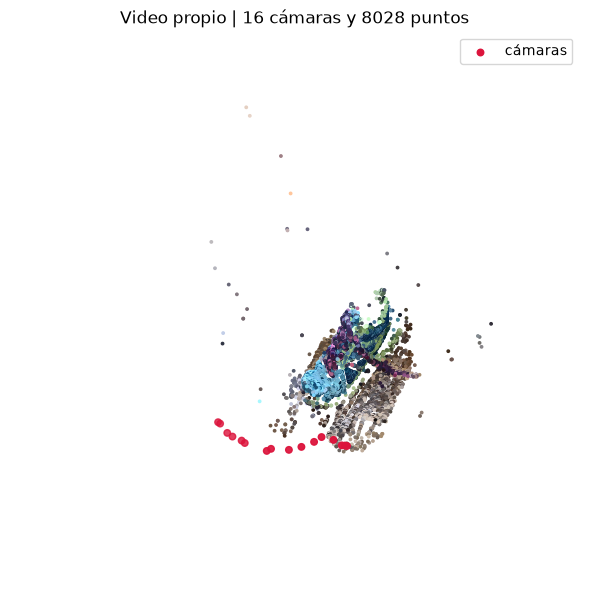

In [31]:
# Se elige la cámara registrada más cercana al centro del recorrido.
fr = min(camaras, key=lambda foto: abs(foto - N // 2))
visibles = [
    xy[foto][indice] for t in puntos for foto, indice in tracks[t] if foto == fr
]
fig, ax = plt.subplots(1, 3, figsize=(15, 5), layout="constrained")
for a in ax:
    a.imshow(fotos[fr])
    a.axis("off")
ax[0].set_title(f"Foto {fr}")
ax[1].scatter(*xy[fr].T, s=3, color="gold")
ax[1].set_title("Features SIFT")
if visibles:
    ax[2].scatter(*np.array(visibles).T, s=4, color="cyan")
ax[2].set_title("Observaciones con punto 3D")
plt.show()

# Misma convención de ejes y colores que usa la nube del notebook base.
xyz = np.array(list(puntos.values()))
fig = plt.figure(figsize=(8, 6), layout="constrained")
ax = fig.add_subplot(projection="3d")
ax.scatter(*a_vista(xyz), c=[
    fotos[foto][int(xy[foto][indice, 1]), int(xy[foto][indice, 0])] / 255
    for foto, indice in (tracks[t][0] for t in puntos)
], s=3, depthshade=False)
ax.scatter(*a_vista([centro(c) for c in camaras.values()]), c="crimson", s=22, label="cámaras")
ax.set_title(f"Video propio | {len(camaras)} cámaras y {len(puntos)} puntos")
ax.set_axis_off()
ax.legend()
plt.show()

**Respuesta.** Con el video propio se registraron las 16 cámaras y se reconstruyeron 8.028 puntos 3D en la escena, con un error medio de reproyección de 0,189 px. El primer par produjo 23 puntos, por debajo del mínimo de 30 correspondencias 2D–3D para intentar registrar otra cámara. El reintento con las fotos 6 y 7 produjo 1.347 puntos iniciales y permitió continuar con el registro incremental.

En la foto 8, los puntos se concentran en la malla, los cordones y los contornos del logo. La goma lisa de la punta y gran parte de la suela lateral tienen menos puntos porque ofrecen menos detalles que se puedan reconocer en varias vistas. También se reconstruye parte del piso, sobre todo donde se ven las vetas de la madera.


#### Resultados de las dos escenas

| Escena | Cámaras registradas | Puntos 3D finales | Error medio de reproyección |
| --- | ---: | ---: | ---: |
| Coliseo (VGGT) | 24/24 | 5.170 | 0,224 px |
| Video propio (zapatilla) | 16/16 | 8.028 | 0,189 px |

Las salidas corresponden a las corridas guardadas de cada escena. Los puntos se cuentan en toda la escena, incluido el fondo. Para evaluar la cobertura, se observa dónde aparecen los puntos sobre cada imagen.


#### **2.- Cinco vecinos En bf.knnMatch, reemplace k=2 por k=5. ¿Cambian los resultados? Explique por qué.**

**Prueba.** Solo se piden cinco vecinos para cada descriptor.

In [32]:
hacer_prueba("k = 5", k=5)

k = 5 {'Lowe': 26970, 'RANSAC': np.int64(19100), 'Pares de fotos': 185, 'Tracks': 1316, 'Puntos iniciales': 83, 'Puntos 3D': 954, 'Cámaras': '24/24', 'Error medio (px)': np.float64(0.34), 'SIFT (s)': 1.89, 'Matching (s)': 0.7, 'Total (s)': 38.74}


**Respuesta.** Se mantuvieron las 26.970 coincidencias que pasan Lowe, las 19.100 verificadas por RANSAC y los 954 puntos finales. Lowe usa el primer y el segundo vecino. Los tres vecinos extra quedan fuera de esa comparación.

####**3.- Test de Lowe: Reemplace 0.8 por 0.6 y luego por 0.95. ¿Cómo varían las parejas y los puntos 3D? ¿Por qué aceptar más parejas no produce más puntos?**

**Prueba.** Se hacen dos corridas independientes para cambiar solo el umbral de Lowe.

In [33]:
hacer_prueba("Lowe = 0.60", lowe=0.6)
hacer_prueba("Lowe = 0.95", lowe=0.95)

Lowe = 0.60 {'Lowe': 18444, 'RANSAC': np.int64(15198), 'Pares de fotos': 185, 'Tracks': 1321, 'Puntos iniciales': 19, 'Puntos 3D': 19, 'Cámaras': '2/24', 'Error medio (px)': np.float64(0.09), 'SIFT (s)': 1.75, 'Matching (s)': 0.3, 'Total (s)': 7.62}
Lowe = 0.95 {'Lowe': 51484, 'RANSAC': np.int64(19867), 'Pares de fotos': 185, 'Tracks': 1047, 'Puntos iniciales': 28, 'Puntos 3D': 28, 'Cámaras': '2/24', 'Error medio (px)': np.float64(0.157), 'SIFT (s)': 1.59, 'Matching (s)': 3.36, 'Total (s)': 10.17}


**Respuesta.** Al bajar a 0,60, Lowe aceptó 18.444 correspondencias y quedaron 15.198 verificadas y 19 puntos 3D. Con 0,95 se aceptaron 51.484 correspondencias, se verificaron 19.867 y quedaron 28 puntos. La base dio 26.970, 19.100 y 954, respectivamente.

Al subir el umbral entran coincidencias más ambiguas. Muchas se descartan con RANSAC. Con 0,95 hubo más verificadas que en la base, pero los tracks bajaron de 1.316 a 1.047. Una coincidencia errónea que pasa RANSAC puede unir observaciones incompatibles e invalidar un track completo. Los puntos 3D también tienen que superar los filtros de triangulación y reproyección. En esta escena, los cambios en Lowe dejaron 19 y 28 puntos en el par inicial, respectivamente. Ambos valores quedaron por debajo de las 30 correspondencias 2D–3D que pide el código para intentar registrar la cámara siguiente.

#### **4.- Menos features: reemplace cv2.SIFT_create(3000) por cv2.SIFT_create(1000). ¿Qué ocurre con los puntos 3D y el tiempo?**

**Prueba.** Se baja el máximo de features solicitados a SIFT. Se miden por separado SIFT y matching para comparar los tiempos.

In [34]:
hacer_prueba("SIFT = 1000", n_features=1000)

SIFT = 1000 {'Lowe': 26970, 'RANSAC': np.int64(19100), 'Pares de fotos': 185, 'Tracks': 1316, 'Puntos iniciales': 83, 'Puntos 3D': 954, 'Cámaras': '24/24', 'Error medio (px)': np.float64(0.34), 'SIFT (s)': 2.36, 'Matching (s)': 0.81, 'Total (s)': 40.45}


**Respuesta.** Las fotos tienen entre 343 y 503 features por imagen, por debajo del límite de 1000. Ambas corridas dieron 954 puntos 3D. SIFT tardó 1,89 s con límite de 3000 y 2,36 s con 1000. Los tiempos totales fueron 44,42 s y 40,45 s, respectivamente. Como el límite nunca se alcanzó, la diferencia de tiempos entre estas dos corridas no permite atribuir un cambio de rendimiento al parámetro.


#### **5.- Menos fotografías: Reemplace N = 24 por N = 12. ¿Se registran todas las cámaras?**

**Prueba.** Se vuelven a seleccionar los cuadros más nítidos en doce tramos del video.

In [35]:
hacer_prueba("N = 12", n_fotos=12)

N = 12 {'Lowe': 7727, 'RANSAC': np.int64(5406), 'Pares de fotos': 65, 'Tracks': 825, 'Puntos iniciales': 58, 'Puntos 3D': 587, 'Cámaras': '12/12', 'Error medio (px)': np.float64(0.321), 'SIFT (s)': 1.04, 'Matching (s)': 0.29, 'Total (s)': 16.91}


**Respuesta.** Sí, se registraron las 12 cámaras. El par inicial produjo 58 puntos y la nube final quedó con 587, frente a los 954 puntos de la base con 24 fotos.

#### **6.- Ángulo de triangulación: En triangular_nuevos, reemplace > 1.5 por > 3. ¿Cuántos puntos se pierden? ¿Por qué un ángulo pequeño da una profundidad poco confiable?**

**Prueba.** Se cambia solo el ángulo mínimo que deben superar los rayos al triangular.

In [36]:
hacer_prueba("Ángulo > 3°", angulo_min=3)

Ángulo > 3° {'Lowe': 26970, 'RANSAC': np.int64(19100), 'Pares de fotos': 185, 'Tracks': 1316, 'Puntos iniciales': 68, 'Puntos 3D': 858, 'Cámaras': '24/24', 'Error medio (px)': np.float64(0.336), 'SIFT (s)': 2.79, 'Matching (s)': 1.05, 'Total (s)': 41.44}


**Respuesta.** El par inicial pasa de 83 a 68 puntos. En la nube final se pasa de 954 a 858 puntos. Se pierden 96 puntos netos. Cuando el ángulo es pequeño, los rayos son casi paralelos. Un error pequeño en la posición de un feature puede desplazar mucho su intersección en profundidad, aunque la reproyección siga cerca de la observación.

### Comparación con la línea de base

La tabla y el gráfico reúnen las corridas hechas con `gato.mp4`. El número de puntos corresponde a la nube después de la limpieza y el ajuste final.

El error medio se calcula sobre las observaciones de los puntos conservados en las cámaras registradas. En las corridas que se quedan en dos cámaras, cubre una parte mucho menor del recorrido.

| Prueba | Lowe | RANSAC | Pares de fotos | Tracks | Puntos iniciales | Puntos 3D | Cámaras | Error medio (px) | SIFT (s) | Matching (s) | Total (s) |
| --- | ---: | ---: | ---: | ---: | ---: | ---: | ---: | ---: | ---: | ---: | ---: |
| Base | 26970 | 19100 | 185 | 1316 | 83 | 954 | 24/24 | 0.34 | 1.89 | 0.7 | 44.42 |
| k = 5 | 26970 | 19100 | 185 | 1316 | 83 | 954 | 24/24 | 0.34 | 1.89 | 0.7 | 38.74 |
| Lowe = 0.60 | 18444 | 15198 | 185 | 1321 | 19 | 19 | 2/24 | 0.09 | 1.75 | 0.3 | 7.62 |
| Lowe = 0.95 | 51484 | 19867 | 185 | 1047 | 28 | 28 | 2/24 | 0.157 | 1.59 | 3.36 | 10.17 |
| SIFT = 1000 | 26970 | 19100 | 185 | 1316 | 83 | 954 | 24/24 | 0.34 | 2.36 | 0.81 | 40.45 |
| N = 12 | 7727 | 5406 | 65 | 825 | 58 | 587 | 12/12 | 0.321 | 1.04 | 0.29 | 16.91 |
| Ángulo > 3° | 26970 | 19100 | 185 | 1316 | 68 | 858 | 24/24 | 0.336 | 2.79 | 1.05 | 41.44 |

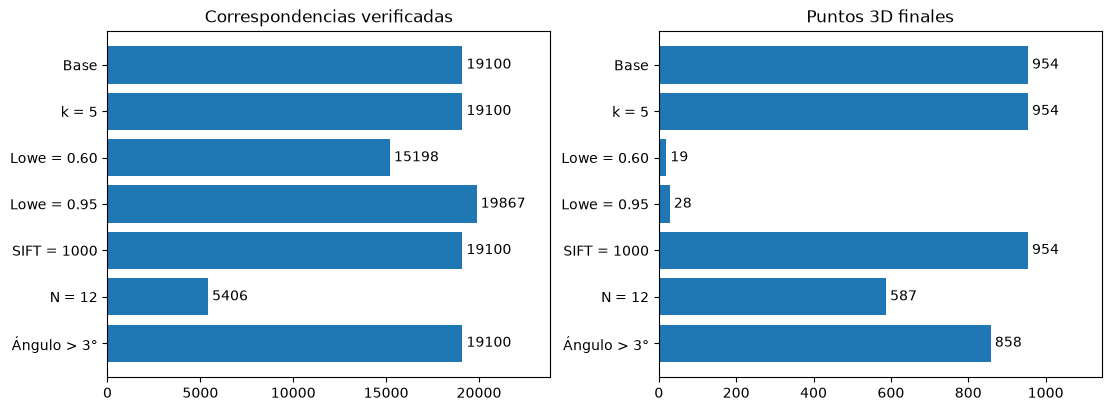

In [37]:
from IPython.display import Markdown, display

nombres = [nombre for nombre in resultados if nombre not in {"Video propio", "VGGT · Colosseum"}]
columnas = list(resultados["Base"])
tabla = [
    "| Prueba | " + " | ".join(columnas) + " |",
    "| --- | " + " | ".join(["---:"] * len(columnas)) + " |",
]
for nombre in nombres:
    tabla.append("| " + nombre + " | " + " | ".join(map(str, resultados[nombre].values())) + " |")
display(Markdown("\n".join(tabla)))

fig, ax = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
for a, medida in zip(ax, ("RANSAC", "Puntos 3D")):
    barras = a.barh(nombres, [resultados[nombre][medida] for nombre in nombres])
    a.bar_label(barras, padding=3)
    a.margins(x=0.2)
    a.invert_yaxis()
    a.set_title("Correspondencias verificadas" if medida == "RANSAC" else "Puntos 3D finales")
plt.show()